# Assignment 2: Module 1, Fuzzy Logic

---

## Practical 8: Sugeno Fuzzy Inference System

### Aim
To implement a simple first-order Sugeno fuzzy inference system in Python.

### Theory
In a Sugeno system, each rule's conclusion is a function of the inputs instead of a fuzzy set. Here each rule has a linear output:

$$z_i = p_i \, x + q_i \, y + r_i$$

The final output is the weighted average of the rule outputs, where each weight $w_i$ is the firing strength of rule $i$:

$$z = \frac{\sum_i w_i z_i}{\sum_i w_i}$$

Because no defuzzification step is needed, Sugeno systems are fast and are often used for optimisation.

scikit-fuzzy has no built-in Sugeno controller, so the system is written directly with NumPy.

### Implementation


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz

# 1. Universe and input membership functions
# The two sets overlap, so every input value has some membership in each input.
u = np.arange(0, 10.01, 0.01)
mf_x = {"Low": fuzz.trimf(u, [0, 0, 6]), "High": fuzz.trimf(u, [4, 10, 10])}
mf_y = {"Low": fuzz.trimf(u, [0, 0, 6]), "High": fuzz.trimf(u, [4, 10, 10])}


In [2]:
# 2. Rules: antecedent terms and linear consequent coefficients (p, q, r)
rules = [
    {"x": "Low",  "y": "Low",  "p": 1.0, "q": 1.0, "r": 0.0},
    {"x": "Low",  "y": "High", "p": 0.0, "q": 2.0, "r": 5.0},
    {"x": "High", "y": "Low",  "p": 2.0, "q": 0.0, "r": 5.0},
    {"x": "High", "y": "High", "p": 3.0, "q": 3.0, "r": 0.0},
]


In [3]:
def sugeno(x0, y0):
    # Fuzzify both inputs
    mu_x = {term: fuzz.interp_membership(u, mf, x0) for term, mf in mf_x.items()}
    mu_y = {term: fuzz.interp_membership(u, mf, y0) for term, mf in mf_y.items()}

    num, den = 0.0, 0.0
    for rule in rules:
        w = min(mu_x[rule["x"]], mu_y[rule["y"]])          # firing strength (AND = min)
        z_i = rule["p"] * x0 + rule["q"] * y0 + rule["r"]  # rule output
        num += w * z_i
        den += w

    return num / den if den > 0 else 0.0

# 3. Test some inputs
for x0, y0 in [(1, 1), (1, 9), (9, 1), (9, 9), (5, 5)]:
    print(f"x = {x0}, y = {y0}  ->  z = {sugeno(x0, y0):.3f}")


x = 1, y = 1  ->  z = 2.000
x = 1, y = 9  ->  z = 23.000
x = 9, y = 1  ->  z = 23.000
x = 9, y = 9  ->  z = 54.000
x = 5, y = 5  ->  z = 17.500


### Visualization


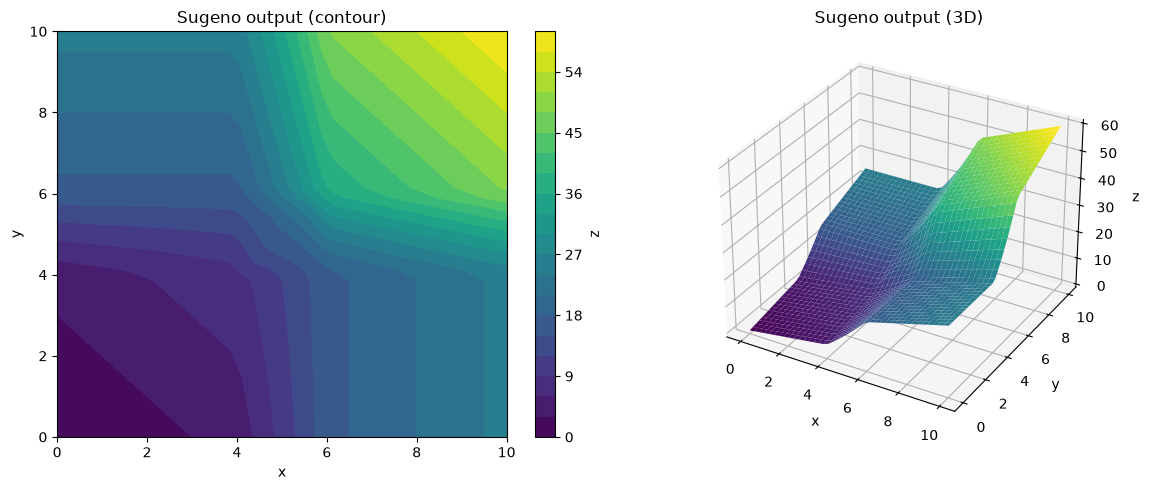

In [4]:
grid = np.linspace(0, 10, 40)
Z = np.array([[sugeno(xi, yi) for xi in grid] for yi in grid])
X, Y = np.meshgrid(grid, grid)

fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(1, 2, 1)
cs = ax1.contourf(X, Y, Z, levels=20, cmap="viridis")
fig.colorbar(cs, ax=ax1, label="z")
ax1.set_xlabel("x")
ax1.set_ylabel("y")
ax1.set_title("Sugeno output (contour)")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(X, Y, Z, cmap="viridis")
ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_zlabel("z")
ax2.set_title("Sugeno output (3D)")

plt.tight_layout()
plt.show()


### Observation
- The corner points match the rule outputs: at $(1, 1)$ only the Low-Low rule is active and gives $z = 2$, and at $(9, 9)$ only the High-High rule is active and gives $z = 54$.
- At $(1, 9)$ and $(9, 1)$ the output is 23, the value of the single active rule.
- At the centre $(5, 5)$ all four rules have equal weight $1/6$, so the output is the average of their outputs $(10 + 15 + 15 + 30) / 4 = 17.5$.

### Conclusion
A first-order Sugeno system was implemented. Its output is the weighted average of linear rule outputs, and the output surface was plotted.
